# U03.E06 · Autoencoder y VAE con Fashion-MNIST

Este notebook **no entrena**: carga los modelos guardados por `scripts/train_ae_vae.py` (semilla 42, AE 6 épocas, VAE 8 épocas),
recalcula las métricas sobre las 10,000 imágenes de prueba y verifica que coinciden con `reports/training_metrics.json`.

Orden de ejecución: `uv run python scripts/train_ae_vae.py --epochs-ae 6 --epochs-vae 8` y después este notebook.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

from inf8239_u03_gen.data import normalize_images, validate_images
from inf8239_u03_gen.evaluation import mean_pairwise_distance, nearest_neighbors, reconstruction_errors

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
SEED = 42
PANEL_SIZE = 16
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
saved = json.loads((ROOT / "reports/training_metrics.json").read_text(encoding="utf-8"))
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 1. Datos y particiones

Fashion-MNIST (Zalando Research, licencia MIT) se descarga con Keras; no se guarda en el repositorio.
El AE usa `validation_split=0.1` (las últimas 6,000 imágenes de entrenamiento); el VAE entrena con las 60,000.
La prueba (10,000) solo se usa para evaluar.

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()
x_train, x_test = normalize_images(x_train), normalize_images(x_test)
validate_images(x_train)
validate_images(x_test)
partitions = pd.DataFrame({
    "partición": ["entrenamiento AE", "validación AE", "entrenamiento VAE", "prueba"],
    "imágenes": [54_000, 6_000, len(x_train), len(x_test)],
})
print(partitions.to_string(index=False))
print("rango de píxeles:", float(x_train.min()), "a", float(x_train.max()))
counts = pd.DataFrame({"train": np.bincount(y_train), "test": np.bincount(y_test)}, index=CLASS_NAMES)
counts.T

        partición  imágenes
 entrenamiento AE     54000
    validación AE      6000
entrenamiento VAE     60000
           prueba     10000
rango de píxeles: 0.0 a 1.0


,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
train,6000,6000,6000,6000,6000,6000,6000,6000,6000,6000
test,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000


## 2. Modelos guardados y métricas de prueba

In [3]:
autoencoder = tf.keras.models.load_model(ROOT / "models/autoencoder.keras")
encoder = tf.keras.models.load_model(ROOT / "models/encoder.keras")
decoder = tf.keras.models.load_model(ROOT / "models/decoder.keras")

ae_test = autoencoder.predict(x_test, batch_size=1024, verbose=0)
test_mean, test_log_variance = encoder.predict(x_test, batch_size=1024, verbose=0)
vae_test = decoder.predict(test_mean, batch_size=1024, verbose=0)
test_kl = -0.5 * np.mean(np.sum(1 + test_log_variance - test_mean ** 2 - np.exp(test_log_variance), axis=1))

ae_errors, vae_errors = reconstruction_errors(x_test, ae_test), reconstruction_errors(x_test, vae_test)
results = pd.DataFrame([
    ["AE · MSE por píxel", ae_errors["mse"], saved["ae_test"]["mse"]],
    ["AE · BCE por imagen", ae_errors["bce_per_image"], saved["ae_test"]["bce_per_image"]],
    ["VAE · MSE por píxel", vae_errors["mse"], saved["vae_test"]["mse"]],
    ["VAE · BCE por imagen", vae_errors["bce_per_image"], saved["vae_test"]["bce_per_image"]],
    ["VAE · KL media", float(test_kl), saved["vae_test_kl"]],
    ["Parámetros AE", autoencoder.count_params(), saved["ae_parameters"]],
    ["Parámetros VAE (codificador + decodificador)", encoder.count_params() + decoder.count_params(), saved["vae_parameters"]],
], columns=["métrica", "recalculada", "training_metrics.json"])
results["coincide"] = np.isclose(results["recalculada"].astype(float), results["training_metrics.json"].astype(float), rtol=1e-5)
assert results["coincide"].all()
results

,métrica,recalculada,training_metrics.json,coincide
0,AE · MSE por píxel,0.020293,0.020293,True
1,AE · BCE por imagen,240.548492,240.548492,True
2,VAE · MSE por píxel,0.033123,0.033123,True
3,VAE · BCE por imagen,267.240540,267.240540,True
4,VAE · KL media,6.338123,6.338123,True
5,Parámetros AE,25888.000000,25888.000000,True
6,Parámetros VAE (codificador + decodificador),202516.000000,202516.000000,True


## 3. Panel no seleccionado: reconstrucción y muestreo

Los 16 índices de prueba y los 16 puntos z ~ N(0, I) salen del mismo generador con semilla 42 que usa el script.
Filas: original, reconstrucción AE, reconstrucción VAE (usando μ) y muestra nueva del VAE.

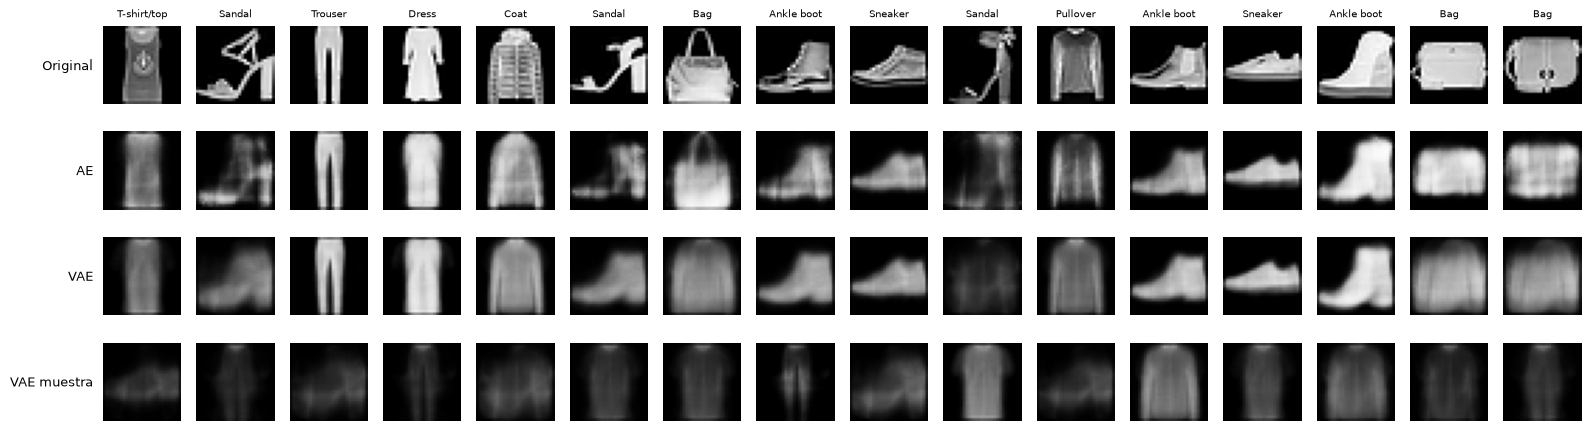

In [4]:
rng = np.random.default_rng(SEED)
indices = np.sort(rng.choice(len(x_test), size=PANEL_SIZE, replace=False))
generated = decoder.predict(rng.normal(size=(PANEL_SIZE, 2)), verbose=0)
assert indices.tolist() == saved["panel_test_indices"]

def show_rows(rows, labels, titles=None):
    figure, axes = plt.subplots(len(rows), PANEL_SIZE, figsize=(PANEL_SIZE, len(rows) + 0.6))
    for row, collection in enumerate(rows):
        for column in range(PANEL_SIZE):
            axes[row, column].imshow(collection[column].squeeze(), cmap="gray", vmin=0, vmax=1)
            axes[row, column].axis("off")
            if titles is not None and titles[row] is not None:
                axes[row, column].set_title(titles[row][column], fontsize=7)
        axes[row, 0].text(-4, 14, labels[row], ha="right", va="center", fontsize=9)
    plt.tight_layout()
    plt.show()

show_rows([x_test[indices], ae_test[indices], vae_test[indices], generated], ["Original", "AE", "VAE", "VAE muestra"],
          [[CLASS_NAMES[y_test[i]] for i in indices], None, None, None])

## 4. Interpolación en el espacio latente del VAE: de (−2, −1) a (2, 1)

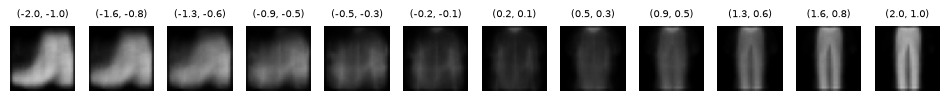

In [5]:
grid = np.array([(1 - value) * np.array([-2.0, -1.0]) + value * np.array([2.0, 1.0]) for value in np.linspace(0, 1, 12)])
interpolation = decoder.predict(grid, verbose=0)
figure, axes = plt.subplots(1, 12, figsize=(12, 1.3))
for axis, image, point in zip(axes, interpolation, grid):
    axis.imshow(image.squeeze(), cmap="gray", vmin=0, vmax=1)
    axis.set_title(f"({point[0]:.1f}, {point[1]:.1f})", fontsize=7)
    axis.axis("off")
plt.show()

## 5. Fidelidad, diversidad y memoria

- **Diversidad**: distancia euclidiana media entre pares de las 16 muestras, comparada con 16 imágenes reales de prueba.
- **Memoria**: distancia de cada muestra a su vecino más cercano en entrenamiento, comparada con la de las imágenes reales de prueba.

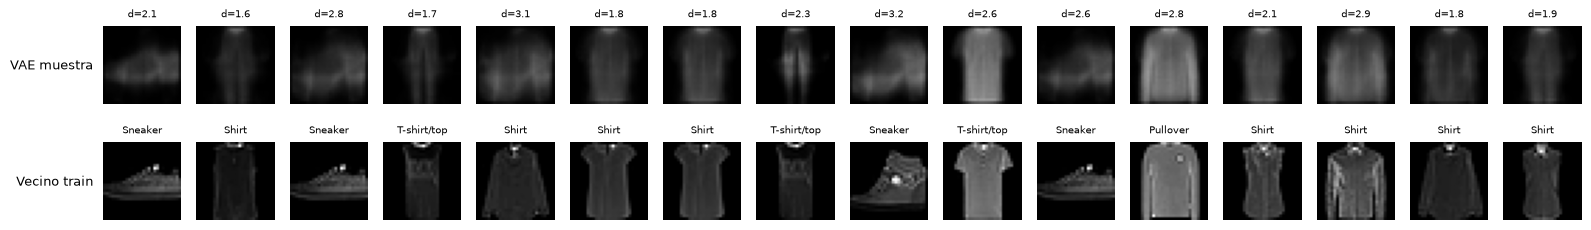

,indicador,recalculado,training_metrics.json,coincide
0,Diversidad · muestras VAE,3.666350,3.666350,True
1,Diversidad · imágenes de prueba,11.664429,11.664429,True
2,Vecino más cercano · muestras VAE (media),2.319645,2.319645,True
3,Vecino más cercano · muestras VAE (mínimo),1.638262,1.638262,True
4,Vecino más cercano · imágenes de prueba (media),3.893456,3.893456,True
5,Vecinos distintos de las 16 muestras,12.000000,12.000000,True
6,Intensidad media · muestras VAE,0.128842,0.128842,True
7,Intensidad media · imágenes de prueba,0.266502,0.266502,True


In [6]:
generated_index, generated_distance = nearest_neighbors(generated, x_train)
_, test_distance = nearest_neighbors(x_test[indices], x_train)
memory = pd.DataFrame([
    ["Diversidad · muestras VAE", mean_pairwise_distance(generated), saved["diversity_generated"]],
    ["Diversidad · imágenes de prueba", mean_pairwise_distance(x_test[indices]), saved["diversity_test_panel"]],
    ["Vecino más cercano · muestras VAE (media)", generated_distance.mean(), saved["nn_distance_generated_mean"]],
    ["Vecino más cercano · muestras VAE (mínimo)", generated_distance.min(), saved["nn_distance_generated_min"]],
    ["Vecino más cercano · imágenes de prueba (media)", test_distance.mean(), saved["nn_distance_test_mean"]],
    ["Vecinos distintos de las 16 muestras", len(set(generated_index.tolist())), saved["nn_unique_generated"]],
    ["Intensidad media · muestras VAE", generated.mean(), saved["mean_intensity_generated"]],
    ["Intensidad media · imágenes de prueba", x_test[indices].mean(), saved["mean_intensity_test_panel"]],
], columns=["indicador", "recalculado", "training_metrics.json"])
memory["coincide"] = np.isclose(memory["recalculado"].astype(float), memory["training_metrics.json"].astype(float), rtol=1e-4)
assert memory["coincide"].all()
show_rows([generated, x_train[generated_index]], ["VAE muestra", "Vecino train"],
          [[f"d={value:.1f}" for value in generated_distance], [CLASS_NAMES[y_train[i]] for i in generated_index]])
memory

## 6. Curvas de entrenamiento

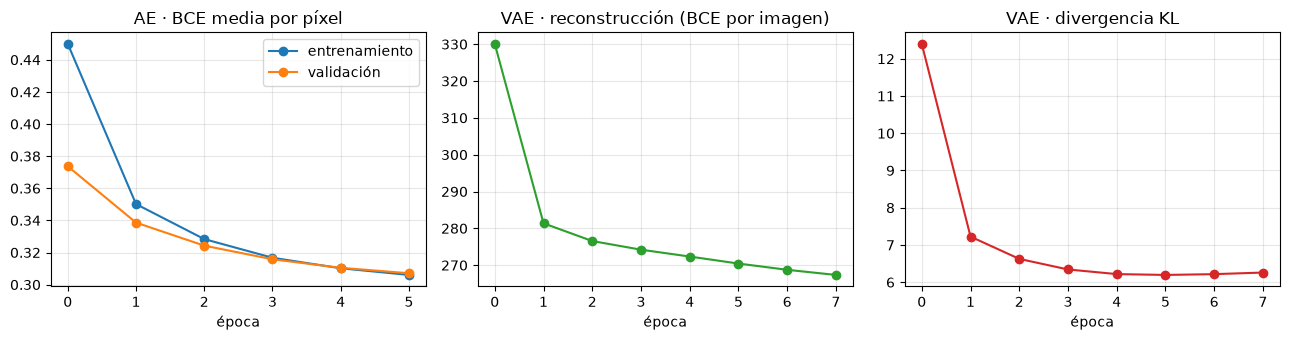

,segundos de entrenamiento,parámetros
AE,18.5,25888
VAE,31.1,202516


In [7]:
history = saved["history"]
figure, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].plot(history["ae"]["loss"], marker="o", label="entrenamiento")
axes[0].plot(history["ae"]["val_loss"], marker="o", label="validación")
axes[0].set_title("AE · BCE media por píxel")
axes[0].legend()
axes[1].plot(history["vae"]["reconstruction"], marker="o", color="tab:green")
axes[1].set_title("VAE · reconstrucción (BCE por imagen)")
axes[2].plot(history["vae"]["kl"], marker="o", color="tab:red")
axes[2].set_title("VAE · divergencia KL")
for axis in axes:
    axis.set_xlabel("época")
    axis.grid(alpha=0.3)
plt.tight_layout()
plt.show()
pd.DataFrame({"segundos de entrenamiento": [saved["ae_train_seconds"], saved["vae_train_seconds"]],
              "parámetros": [saved["ae_parameters"], saved["vae_parameters"]]}, index=["AE", "VAE"]).round(1)

## 7. Lectura

- El AE (latente 16) reconstruye mejor que el VAE (latente 2) en MSE y BCE; un error bajo no lo convierte en generador.
- Las muestras del VAE son siluetas reconocibles pero oscuras y borrosas, con menos diversidad que las imágenes reales.
- Las muestras quedan más cerca del entrenamiento que las imágenes de prueba, pero el panel de vecinos muestra promedios difusos, no copias; la distancia L2 en píxeles no es una prueba de privacidad.
- Uso previsto: demostración académica del espacio latente. Detalle en `MODEL_CARD.md` y `reports/cierre_interpretativo.md`.